# 3. Transformer Encoder

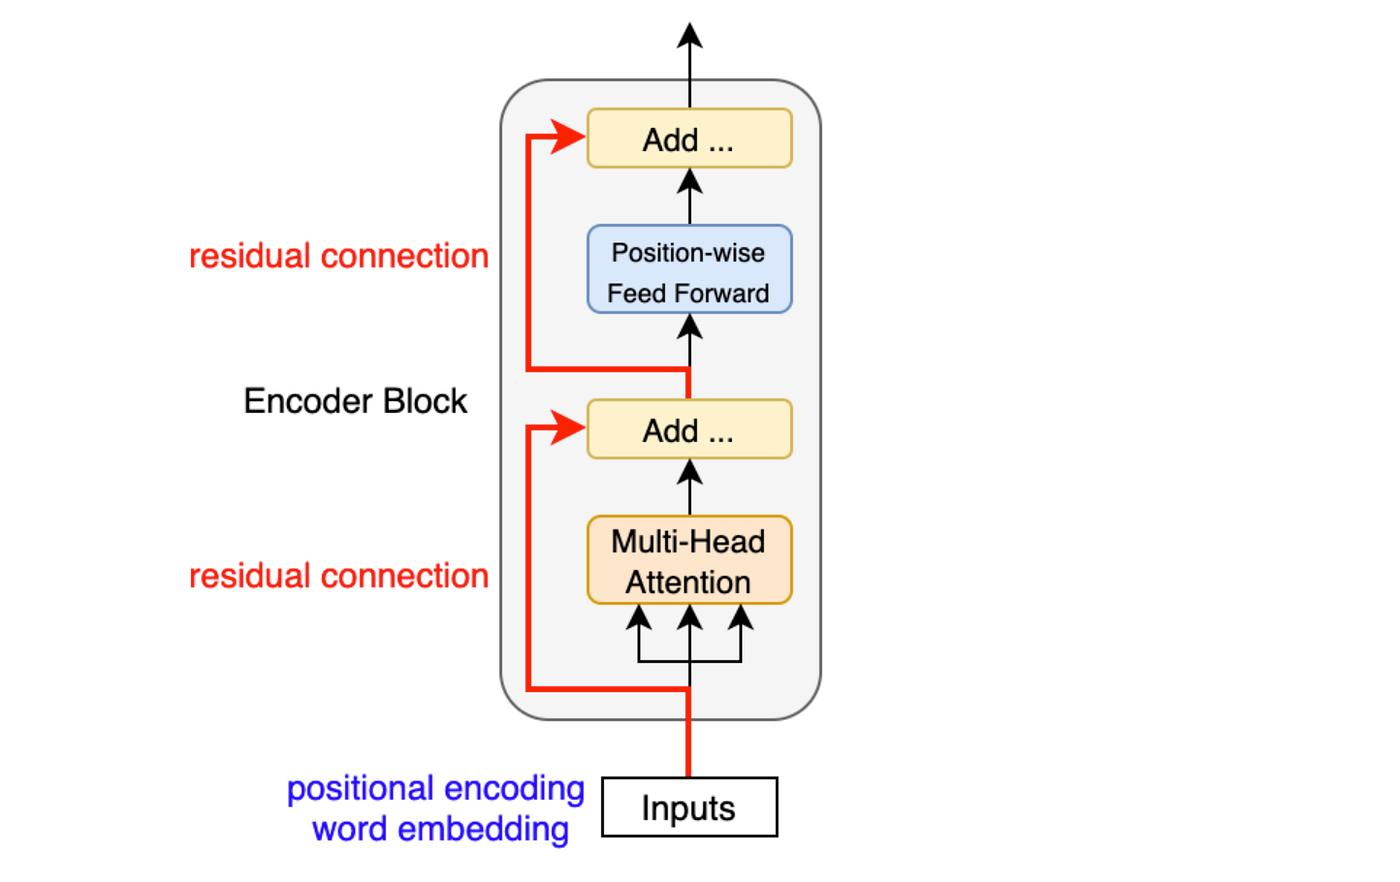

The **Transformer encoder** is responsible for converting the input/source sequence into **contextual representations**.

A Transformer encoder layer contains:

1. **Multi-Head Self-Attention**
2. **Residual Connection**
3. **Layer Normalization**
4. **Feed-Forward Network**
5. **Another Residual Connection**
6. **Another Layer Normalization**



---

## 3.1 Encoder Block — High-Level View

```text
Input
  │
  ▼
Multi-Head Self-Attention
  │
  ▼
Add & Norm
  │
  ▼
Feed-Forward Network
  │
  ▼
Add & Norm
  │
  ▼
Output
```

More explicitly:

```text
                 ┌─────────────────────────────┐
                 │                             │
                 │      Residual Connection    │
                 │                             │
Input ───────────┼──► Multi-Head Self-Attention │
  │              │              │              │
  │              └──────────────┘              │
  │                            ↓                │
  │                         Add + Norm          │
  │                            ↓                │
  │              ┌─────────────────────────────┐│
  │              │ Feed-Forward Network       ││
  │              └─────────────────────────────┘│
  │                            ↓                │
  └──────────────────────► Add + Norm ─────────┘
                               ↓
                             Output
```

---

## 3.2 Step 1 — Multi-Head Self-Attention

The first major operation is **multi-head self-attention**.

Given an input sequence:

```text
"The cat sat"
```

each token can attend to other tokens:

```text
        The
       ↙   ↘
     cat ←→ sat
```

The key word is **self**:

> The queries, keys, and values all originate from the same input sequence.

For self-attention:

$$
Q = XW_Q
$$

$$
K = XW_K
$$

$$
V = XW_V
$$

The scaled dot-product attention is:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

Multi-head attention performs this attention operation using multiple learned attention heads:

$$
\operatorname{MultiHead}(Q,K,V)
=
\operatorname{Concat}
(\text{head}_1,\ldots,\text{head}_h)W_O
$$

Each head can learn different relationships between tokens.

---

## 3.3 Step 2 — Residual Connection

After self-attention, the result is combined with the original input.

Conceptually:

```text
Input ──────────────────────┐
  │                         │
  ▼                         │
Self-Attention              │
  │                         │
  └───────────────► Add ◄───┘
                       │
                       ▼
                    LayerNorm
```

Mathematically:

$$
Y = \operatorname{LayerNorm}
\left(
X + \operatorname{SelfAttention}(X)
\right)
$$

The term:

$$
X + \operatorname{SelfAttention}(X)
$$

is the **residual connection**.

### Why?

Residual connections provide a direct path for information and gradients through the network.

This makes deep Transformer stacks easier to optimize.

---

## 3.4 Step 3 — Layer Normalization

After the residual addition, **LayerNorm** is applied.

```text
Self-Attention
      ↓
Residual Addition
      ↓
LayerNorm
```

Layer normalization helps keep activations well-behaved during training.

For an input vector \(x\), LayerNorm conceptually normalizes its features:

$$
\operatorname{LayerNorm}(x)
=
\gamma
\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}
+\beta
$$

where:

- $\mu$ = mean of the features
- $\sigma^2$ = variance of the features
- $\epsilon$ = small value for numerical stability
- $\gamma$ = learnable scale
- $\beta$ = learnable shift

---

## 3.5 Step 4 — Feed-Forward Network

After attention and normalization, the representation passes through a **position-wise Feed-Forward Network (FFN)**.

Conceptually:

```text
Input
  ↓
Linear
  ↓
Activation
  ↓
Linear
  ↓
Output
```

A common formulation is:

$$
\operatorname{FFN}(x)
=
W_2\,\sigma(W_1x+b_1)+b_2
$$

where \($\sigma$) is an activation function.

In the original Transformer, the FFN uses **ReLU**:

$$
\operatorname{FFN}(x)
=
\operatorname{ReLU}(xW_1+b_1)W_2+b_2
$$

The important point is:

> **Self-attention mixes information across tokens, while the FFN performs a learned transformation independently at each token position.**

---

## 3.6 Step 5 — Second Residual Connection

The FFN output is again combined with its input.

```text
Input to FFN ───────────────────┐
       │                        │
       ▼                        │
      FFN                       │
       │                        │
       └──────────────► Add ◄───┘
                          │
                          ▼
                       LayerNorm
```

Mathematically:

$$
Z =
\operatorname{LayerNorm}
\left(
Y+\operatorname{FFN}(Y)
\right)
$$

where \(Y\) is the output from the previous sublayer.

---

# 3.7 Complete Encoder Layer

Putting everything together:

```text
                     ┌─────────────────────┐
                     │                     │
                     │  Residual Path      │
                     │                     │
Input ───────────────► Multi-Head          │
                     │ Self-Attention      │
                     └──────────┬──────────┘
                                ↓
                         Add + LayerNorm
                                ↓
                     ┌─────────────────────┐
                     │ Feed-Forward       │
                     │ Network             │
                     └──────────┬──────────┘
                                ↓
                         Add + LayerNorm
                                ↓
                              Output
```

A compact mathematical representation is:

$$
Y =
\operatorname{LayerNorm}
\left(
X+\operatorname{MHA}(X)
\right)
$$

then:

$$
Z =
\operatorname{LayerNorm}
\left(
Y+\operatorname{FFN}(Y)
\right)
$$

---

## 3.8 What Each Component Does

| Component | Main purpose |
|---|---|
| **Multi-Head Self-Attention** | Allows tokens to interact with one another |
| **Residual Connection** | Provides a direct information/gradient path |
| **LayerNorm** | Normalizes activations and helps stable optimization |
| **Feed-Forward Network** | Applies nonlinear transformation to token representations |
| **Encoder Layer** | Combines all these operations into one contextual processing block |

---

## 3.9 The Most Important Mental Model

Think of the encoder layer as:

```text
Input
  ↓
"Which other tokens are relevant?"
  ↓
Self-Attention
  ↓
"Preserve original information + attention information"
  ↓
Residual + Norm
  ↓
"Transform each token representation"
  ↓
Feed-Forward Network
  ↓
"Preserve previous information + transformed information"
  ↓
Residual + Norm
  ↓
Output
```

### Key distinction

**Attention:**

> Mixes information **between tokens**.

**FFN:**

> Transforms information **within each token representation**.

This distinction is extremely useful for understanding Transformer architecture.

---

## 3.10 Stacking Encoder Layers

A Transformer does not normally use just one encoder layer.

Multiple encoder layers are stacked:

```text
Input
  ↓
Encoder Layer 1
  ↓
Encoder Layer 2
  ↓
Encoder Layer 3
  ↓
...
  ↓
Encoder Layer N
  ↓
Encoder Output
```

Each layer progressively transforms the representations.

Conceptually:

```text
Lower layers
     ↓
Local / basic relationships
     ↓
Middle layers
     ↓
More complex contextual relationships
     ↓
Higher layers
     ↓
Rich contextual representations
```

---

## Interview Points 🎯

### What are the main components of a Transformer encoder?

> Multi-head self-attention followed by a position-wise feed-forward network, with residual connections and layer normalization around the sublayers.

### What does self-attention do?

> It allows each token to incorporate information from other tokens in the sequence.

### What does the FFN do?

> It applies a nonlinear transformation independently to each token representation.

### Why residual connections?

> They provide direct information and gradient paths, making deeper networks easier to optimize.

### Why LayerNorm?

> It normalizes the activations and helps stabilize and optimize Transformer training.

---

## What You Should Remember

1. A Transformer encoder consists of **self-attention + FFN** sublayers.
2. **Multi-head self-attention** allows tokens to exchange information.
3. **Residual connections** add the sublayer input back to its output.
4. **LayerNorm** helps stabilize the representations and training.
5. The FFN transforms each token representation **independently**.
6. The encoder layer can be summarized as:

$$
X
\rightarrow
\text{MHA}
\rightarrow
\text{Add \& Norm}
\rightarrow
\text{FFN}
\rightarrow
\text{Add \& Norm}
\rightarrow
Z
$$

7. Multiple encoder layers are **stacked** to build the complete Transformer encoder.

---